# Heart Disease Prediction

Can routine clinical measurements (age, chest-pain type, maximum heart rate, ST depression, etc.) predict whether a patient has heart disease?
This notebook compares four classifiers on the UCI Heart Disease dataset. Recall on the disease class matters most, because a missed diagnosis is costlier than a false alarm.

**Two findings before modelling:**

1. **Duplicates.** 723 of the 1,025 rows are exact duplicates. Removing them leaves **302 unique patients**. Skipping this step lets duplicates leak between the train and test sets and inflates accuracy towards ~100%.
2. **A flipped label.** In this Kaggle version, *target* = 1 means the patient does **not** have heart disease. Every clinical sign points the other way (section 4), so I flip the label before modelling. Without the flip, the "disease recall" would really be the recall on healthy patients.

In [1]:
# ========================================
# 1. IMPORT LIBRARIES
# ========================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report,
                             roc_curve, roc_auc_score)
import os
import warnings
warnings.filterwarnings('ignore')
os.makedirs('images', exist_ok=True)

## 1. Load data

In [2]:
# ========================================
# 2. LOAD DATASET
# ========================================
df = pd.read_csv('data/heart.csv')

print("="*50)
print("DATASET LOADED SUCCESSFULLY")
print("="*50)
print(f"\nDataset Shape: {df.shape}")
print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}")
print(f"\n")

DATASET LOADED SUCCESSFULLY

Dataset Shape: (1025, 14)
Rows: 1025, Columns: 14




## 2. First look

In [3]:
# ========================================
# 3. EDA
# ========================================
print("\n" + "="*50)
print("FIRST 5 ROWS")
print("="*50)
print(df.head())

print("\n" + "="*50)
print("DATASET INFO")
print("="*50)
print(df.info())

print("\n" + "="*50)
print("STATISTICAL SUMMARY")
print("="*50)
print(df.describe())

print("\n" + "="*50)
print("MISSING VALUES CHECK")
print("="*50)
print(df.isnull().sum())

print("\n" + "="*50)
print("TARGET VARIABLE DISTRIBUTION")
print("="*50)
print(df['target'].value_counts())


FIRST 5 ROWS
   age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  \
0   52    1   0       125   212    0        1      168      0      1.0      2   
1   53    1   0       140   203    1        0      155      1      3.1      0   
2   70    1   0       145   174    0        1      125      1      2.6      0   
3   61    1   0       148   203    0        1      161      0      0.0      2   
4   62    0   0       138   294    1        1      106      0      1.9      1   

   ca  thal  target  
0   2     3       0  
1   0     3       0  
2   0     3       0  
3   1     3       0  
4   3     2       0  

DATASET INFO
<class 'pandas.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non

In [4]:
# ========================================
# 4. SET STYLE
# ========================================
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

## 3. Duplicate check

The raw file has 1,025 rows, but most are copies of the same patients. If duplicates stay in, an identical record can land in both the train and test sets, and the model is rewarded for memorising rather than generalising.

In [5]:
# What happens if we DON'T remove duplicates?
Xd, yd = df.drop('target', axis=1), df['target']
Xd_tr, Xd_te, yd_tr, yd_te = train_test_split(Xd, yd, test_size=0.2, random_state=42, stratify=yd)
seen = set(map(tuple, Xd_tr.values))
leaked = sum(tuple(r) in seen for r in Xd_te.values)
rf_leaky = RandomForestClassifier(random_state=42).fit(Xd_tr, yd_tr)
print(f"Test rows that also appear in train: {leaked} / {len(Xd_te)}")
print(f"Random Forest 'accuracy' with duplicates: {rf_leaky.score(Xd_te, yd_te):.3f}  <- misleading")

Test rows that also appear in train: 202 / 205
Random Forest 'accuracy' with duplicates: 1.000  <- misleading


In [6]:
duplicates = df.duplicated().sum()
print(f"Duplicate rows: {duplicates} of {len(df)}")
df = df.drop_duplicates().reset_index(drop=True)
print(f"Unique patients: {df.shape[0]}")
print(df['target'].value_counts())

Duplicate rows: 723 of 1025
Unique patients: 302
target
1    164
0    138
Name: count, dtype: int64


## 4. Label check

The dataset description says 1 = disease, but does the data agree? A quick test is to compare the two groups with what cardiologists already know: patients with heart disease tend to be older and more often male, get angina during exercise, show more ST depression and more blocked vessels, and reach a lower maximum heart rate.

In [7]:
# ========================================
# 5. LABEL CHECK
# ========================================
clinical_signs = ['age', 'sex', 'exang', 'oldpeak', 'ca', 'thalach']
print(df.groupby('target')[clinical_signs].mean().round(2))

          age   sex  exang  oldpeak    ca  thalach
target                                            
0       56.60  0.83   0.55     1.59  1.17   139.10
1       52.59  0.56   0.14     0.59  0.34   158.38


Every sign points to *target* = 0 as the sick group: older patients (56.6 vs 52.6 years), more men (83% vs 56%), more exercise angina (55% vs 14%), more ST depression (1.59 vs 0.59), more blocked vessels (1.17 vs 0.34) and a lower maximum heart rate (139 vs 158).

The counts agree too. After removing duplicates there are 164 patients with *target* = 1, exactly the number of healthy patients in the original UCI Cleveland data (164 healthy, 139 sick). So the label is stored the other way round, and I flip it: from here on 1 = disease, and every precision, recall and F1 below is about the sick patients.

In [8]:
df['target'] = 1 - df['target']  # 1 = disease from here on
print(df['target'].value_counts().sort_index().rename({0: 'No disease (0)', 1: 'Disease (1)'}))

target
No disease (0)    164
Disease (1)       138
Name: count, dtype: int64


## 5. Exploratory analysis (on the de-duplicated data)

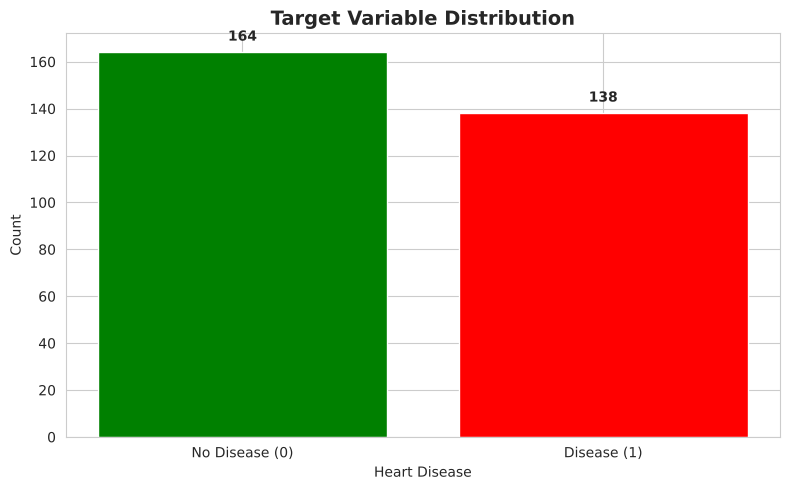

In [9]:
# ========================================
# 6. EXPLORATORY DATA ANALYSIS (EDA)
# ========================================

# 6.1 Target Distribution
plt.figure(figsize=(8, 5))
target_counts = df['target'].value_counts().sort_index()  # 0 then 1, the same order as the bar labels
plt.bar(['No Disease (0)', 'Disease (1)'], target_counts.values, color=['green', 'red'])
plt.title('Target Variable Distribution', fontsize=14, fontweight='bold')
plt.ylabel('Count')
plt.xlabel('Heart Disease')
for i, v in enumerate(target_counts.values):
    plt.text(i, v + 5, str(v), ha='center', fontweight='bold')
plt.tight_layout()
plt.savefig('images/target_distribution.png', dpi=300)
plt.show()

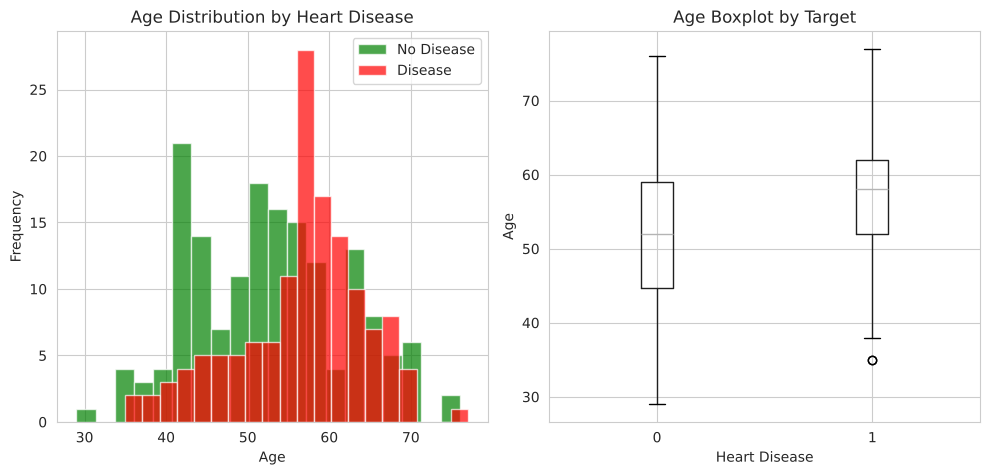

In [10]:
# 6.2 Age Distribution by Target
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.hist(df[df['target']==0]['age'], bins=20, alpha=0.7, label='No Disease', color='green')
plt.hist(df[df['target']==1]['age'], bins=20, alpha=0.7, label='Disease', color='red')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.title('Age Distribution by Heart Disease')
plt.legend()

plt.subplot(1, 2, 2)
df.boxplot(column='age', by='target', ax=plt.gca())
plt.suptitle('')
plt.title('Age Boxplot by Target')
plt.xlabel('Heart Disease')
plt.ylabel('Age')
plt.tight_layout()
plt.savefig('images/age_analysis.png', dpi=300)
plt.show()

Correlations with disease: exercise-induced angina (*exang*, 0.44), ST depression (*oldpeak*, 0.43), number of major vessels (*ca*, 0.41) and *thal* (0.34) correlate positively, while chest-pain type (*cp*, -0.43), max heart rate (*thalach*, -0.42) and slope (-0.34) correlate negatively. That matches clinical knowledge: a heart that can't reach a high rate under stress is a classic warning sign. *cp* is negative because code 0 in this version is asymptomatic chest pain, the type most common in sick patients (73% of the 143 patients with *cp* = 0 have heart disease).

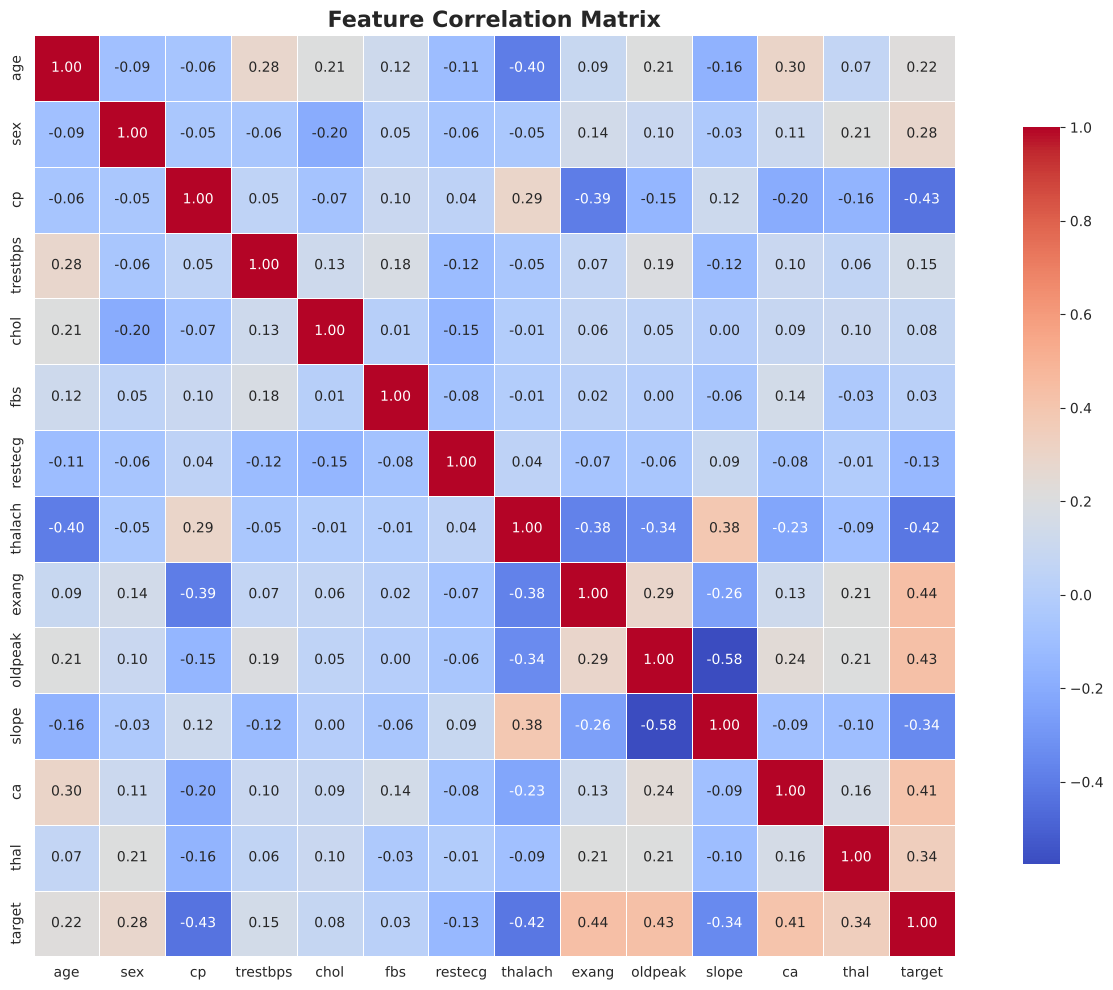

In [11]:
# 6.3 Correlation Matrix
plt.figure(figsize=(14, 10))
correlation = df.corr()
sns.heatmap(correlation, annot=True, fmt='.2f', cmap='coolwarm',
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title('Feature Correlation Matrix', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig('images/correlation_matrix.png', dpi=300)
plt.show()

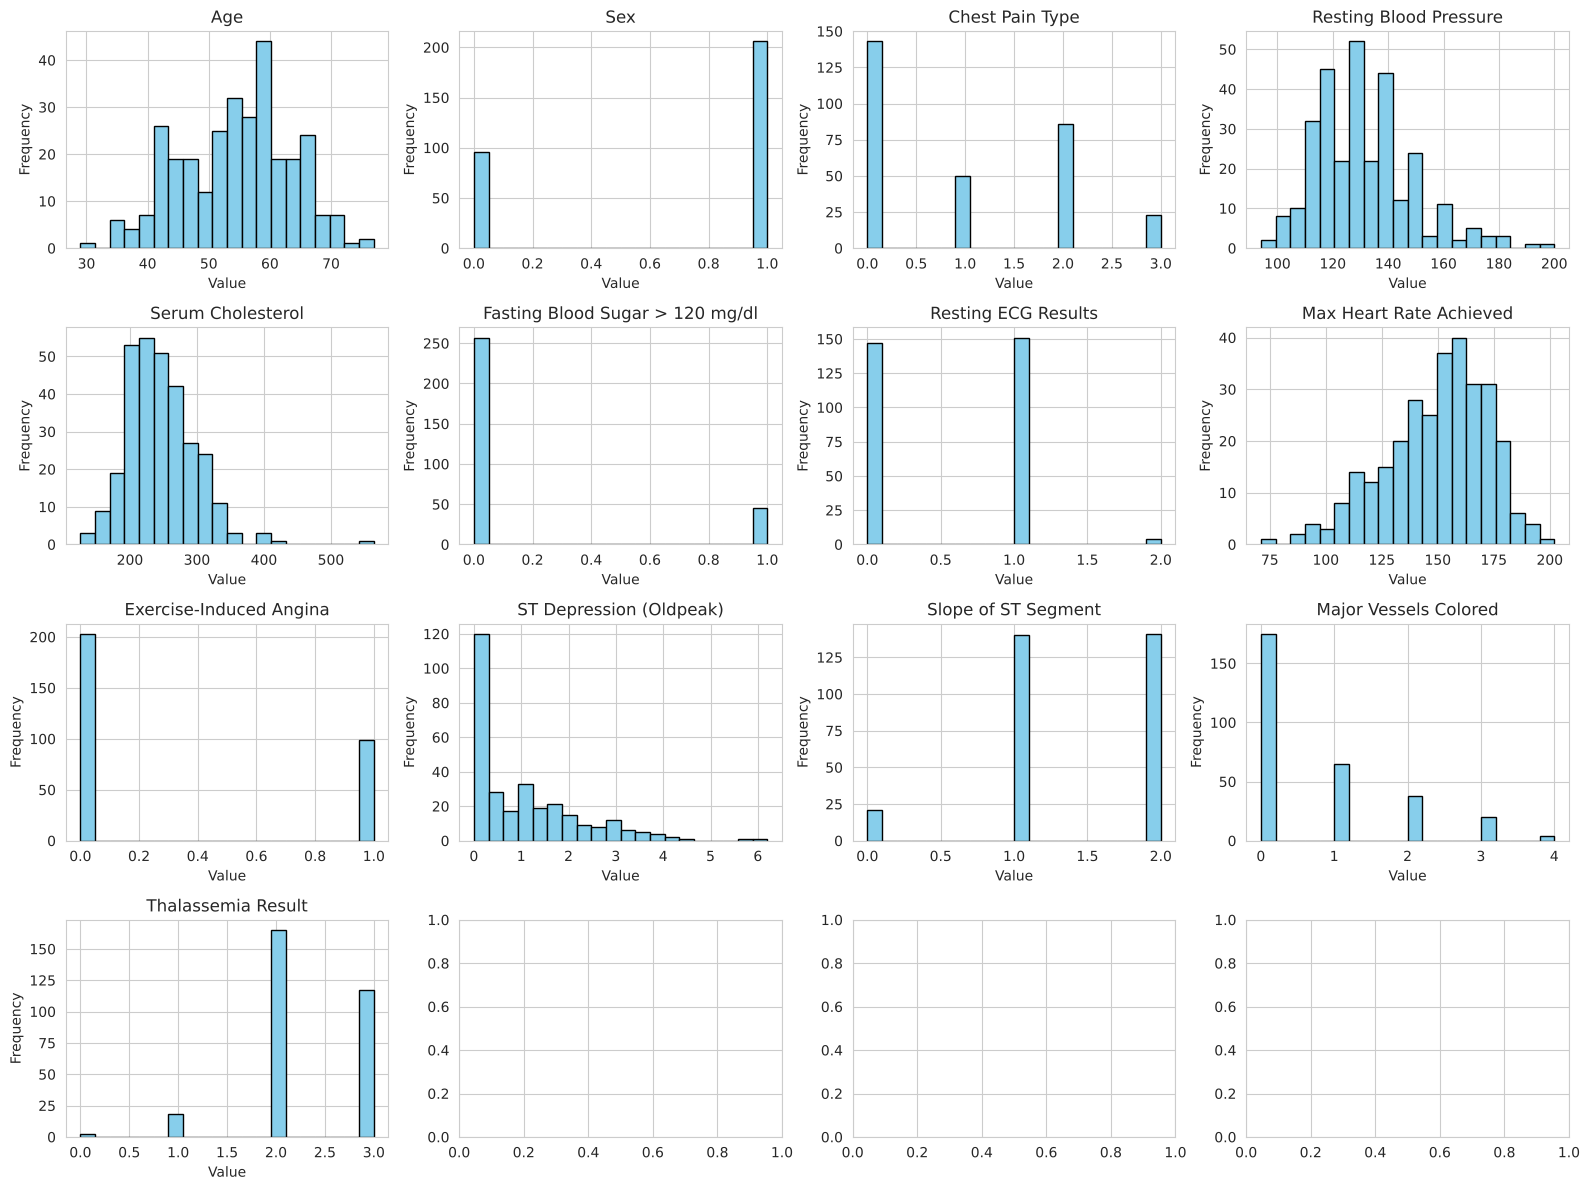

In [12]:
# 6.4 Feature Distributions

feature_names = {
    'age': 'Age',
    'sex': 'Sex',
    'cp': 'Chest Pain Type',
    'trestbps': 'Resting Blood Pressure',
    'chol': 'Serum Cholesterol',
    'fbs': 'Fasting Blood Sugar > 120 mg/dl',
    'restecg': 'Resting ECG Results',
    'thalach': 'Max Heart Rate Achieved',
    'exang': 'Exercise-Induced Angina',
    'oldpeak': 'ST Depression (Oldpeak)',
    'slope': 'Slope of ST Segment',
    'ca': 'Major Vessels Colored',
    'thal': 'Thalassemia Result',
    'target': 'Heart Disease Presence'
}

fig, axes = plt.subplots(4, 4, figsize=(16, 12))
features = df.drop('target', axis=1).columns

for idx, feature in enumerate(features):
    row = idx // 4
    col = idx % 4
    axes[row, col].hist(df[feature], bins=20, color='skyblue', edgecolor='black')
    axes[row, col].set_title(feature_names.get(feature, feature))
    axes[row, col].set_xlabel('Value')
    axes[row, col].set_ylabel('Frequency')

plt.tight_layout()
plt.savefig('images/feature_distributions.png', dpi=300)
plt.show()

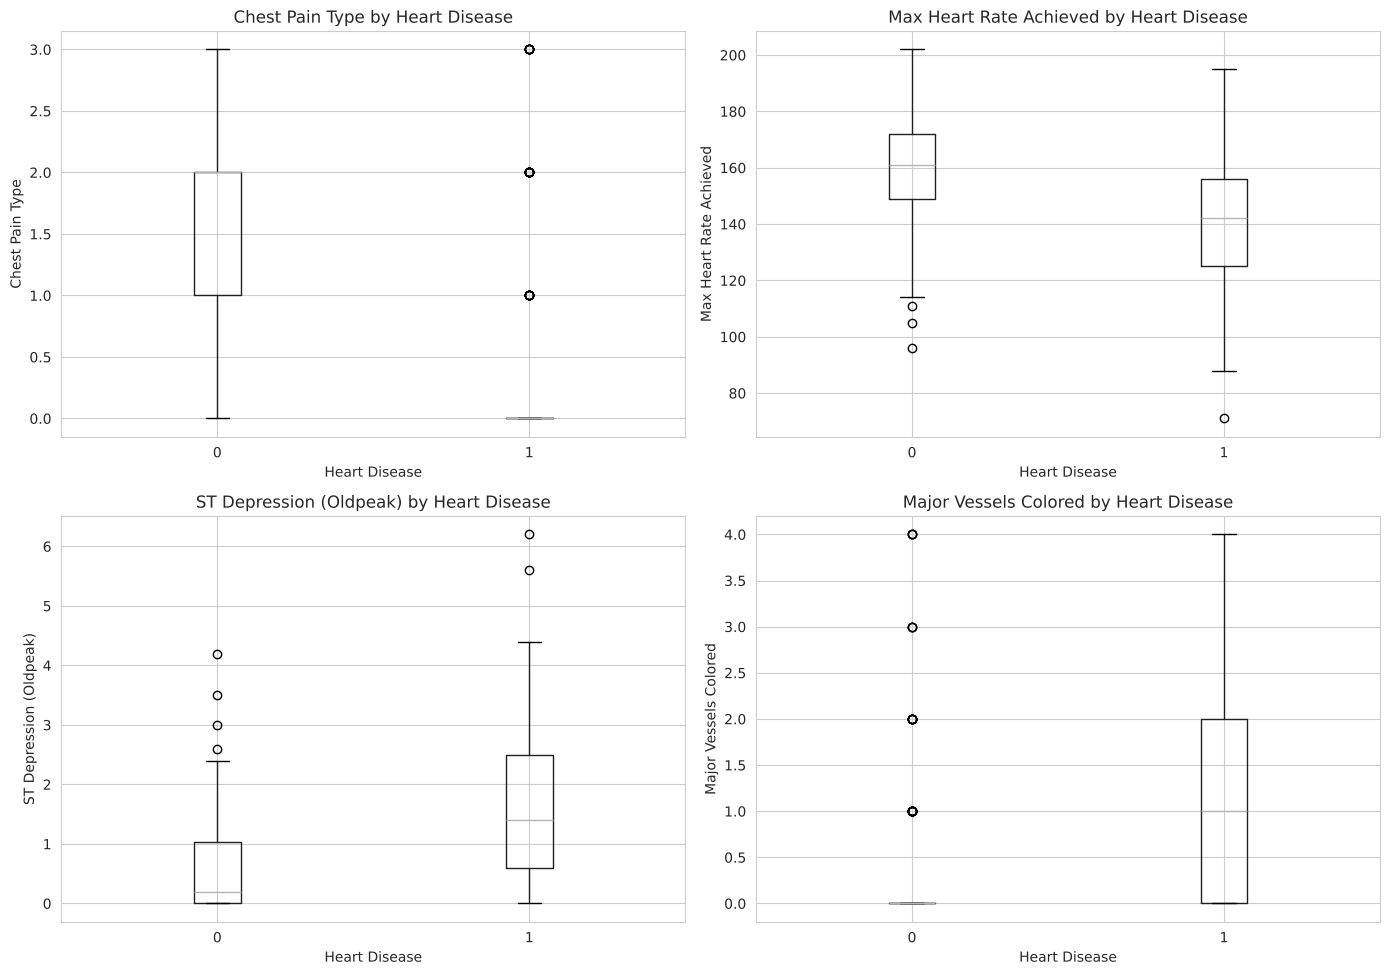

In [13]:
# 6.5 Key Features vs Target
key_features = ['cp', 'thalach', 'oldpeak', 'ca']

feature_names = {
    'cp': 'Chest Pain Type',
    'thalach': 'Max Heart Rate Achieved',
    'oldpeak': 'ST Depression (Oldpeak)',
    'ca': 'Major Vessels Colored'
}

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for idx, feature in enumerate(key_features):
    row = idx // 2
    col = idx % 2
    df.boxplot(column=feature, by='target', ax=axes[row, col])
    axes[row, col].set_title(f'{feature_names[feature]} by Heart Disease')
    axes[row, col].set_xlabel('Heart Disease')
    axes[row, col].set_ylabel(feature_names[feature])

plt.suptitle('')
plt.tight_layout()
plt.savefig('images/key_features_boxplot.png', dpi=300)
plt.show()

## 6. Train/test split & scaling

A stratified 80/20 split keeps the class balance the same in both sets. The scaler is fit on the training set only to avoid leakage.

In [14]:
X = df.drop('target', axis=1)
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f"Training set: {X_train.shape[0]} patients")
print(f"Test set:     {X_test.shape[0]} patients")

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Training set: 241 patients
Test set:     61 patients


## 7. Baseline models

Four model families: linear (Logistic Regression), ensemble (Random Forest), kernel (SVM) and instance-based (KNN).

In [15]:
# ========================================
# 7. MODEL
# ========================================
print("\n" + "="*50)
print("MODEL PERFORMANCE")
print("="*50)

# Initialize models
models = {
    'Logistic Regression': LogisticRegression(random_state=42, max_iter=1000),
    'Random Forest': RandomForestClassifier(random_state=42),
    'SVM': SVC(random_state=42, probability=True),
    'K-Nearest Neighbors': KNeighborsClassifier()
}

# Train models and store results
results = {}
predictions = {}

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    predictions[name] = y_pred

    # Calculate metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    results[name] = {
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1
    }

    print(f"{name} - Accuracy: {accuracy:.4f}")

print("\n")


MODEL PERFORMANCE
Logistic Regression - Accuracy: 0.7869
Random Forest - Accuracy: 0.8033
SVM - Accuracy: 0.8197
K-Nearest Neighbors - Accuracy: 0.8033




## 8. Hyperparameter tuning (Random Forest)

A 5-fold grid search over 108 combinations.

In [16]:
# ========================================
# 8. HYPERPARAMETER TUNING
# ========================================
print("\n" + "="*50)
print("HYPERPARAMETER TUNING (Random Forest)")
print("="*50)

# Define parameter grid
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [5, 10, 20, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

# Grid search
grid_search = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)

print("Running GridSearchCV...")
grid_search.fit(X_train_scaled, y_train)

print(f"\nBest parameters: {grid_search.best_params_}")
print(f"Best cross-validation score: {grid_search.best_score_:.4f}")

# Train optimized model
best_rf = grid_search.best_estimator_
y_pred_tuned = best_rf.predict(X_test_scaled)

# Update results with tuned model
results['Random Forest (Tuned)'] = {
    'Accuracy': accuracy_score(y_test, y_pred_tuned),
    'Precision': precision_score(y_test, y_pred_tuned),
    'Recall': recall_score(y_test, y_pred_tuned),
    'F1-Score': f1_score(y_test, y_pred_tuned)
}
predictions['Random Forest (Tuned)'] = y_pred_tuned

print(f"\nTuned Random Forest - Accuracy: {results['Random Forest (Tuned)']['Accuracy']:.4f}")


HYPERPARAMETER TUNING (Random Forest)
Running GridSearchCV...


Fitting 5 folds for each of 108 candidates, totalling 540 fits



Best parameters: {'max_depth': 10, 'min_samples_leaf': 2, 'min_samples_split': 10, 'n_estimators': 50}
Best cross-validation score: 0.8466

Tuned Random Forest - Accuracy: 0.8197


## 9. Model comparison


MODEL COMPARISON

                        Accuracy  Precision  Recall  F1-Score
Logistic Regression      0.7869     0.7778  0.7500    0.7636
Random Forest            0.8033     0.7857  0.7857    0.7857
SVM                      0.8197     0.8148  0.7857    0.8000
K-Nearest Neighbors      0.8033     0.7857  0.7857    0.7857
Random Forest (Tuned)    0.8197     0.7742  0.8571    0.8136




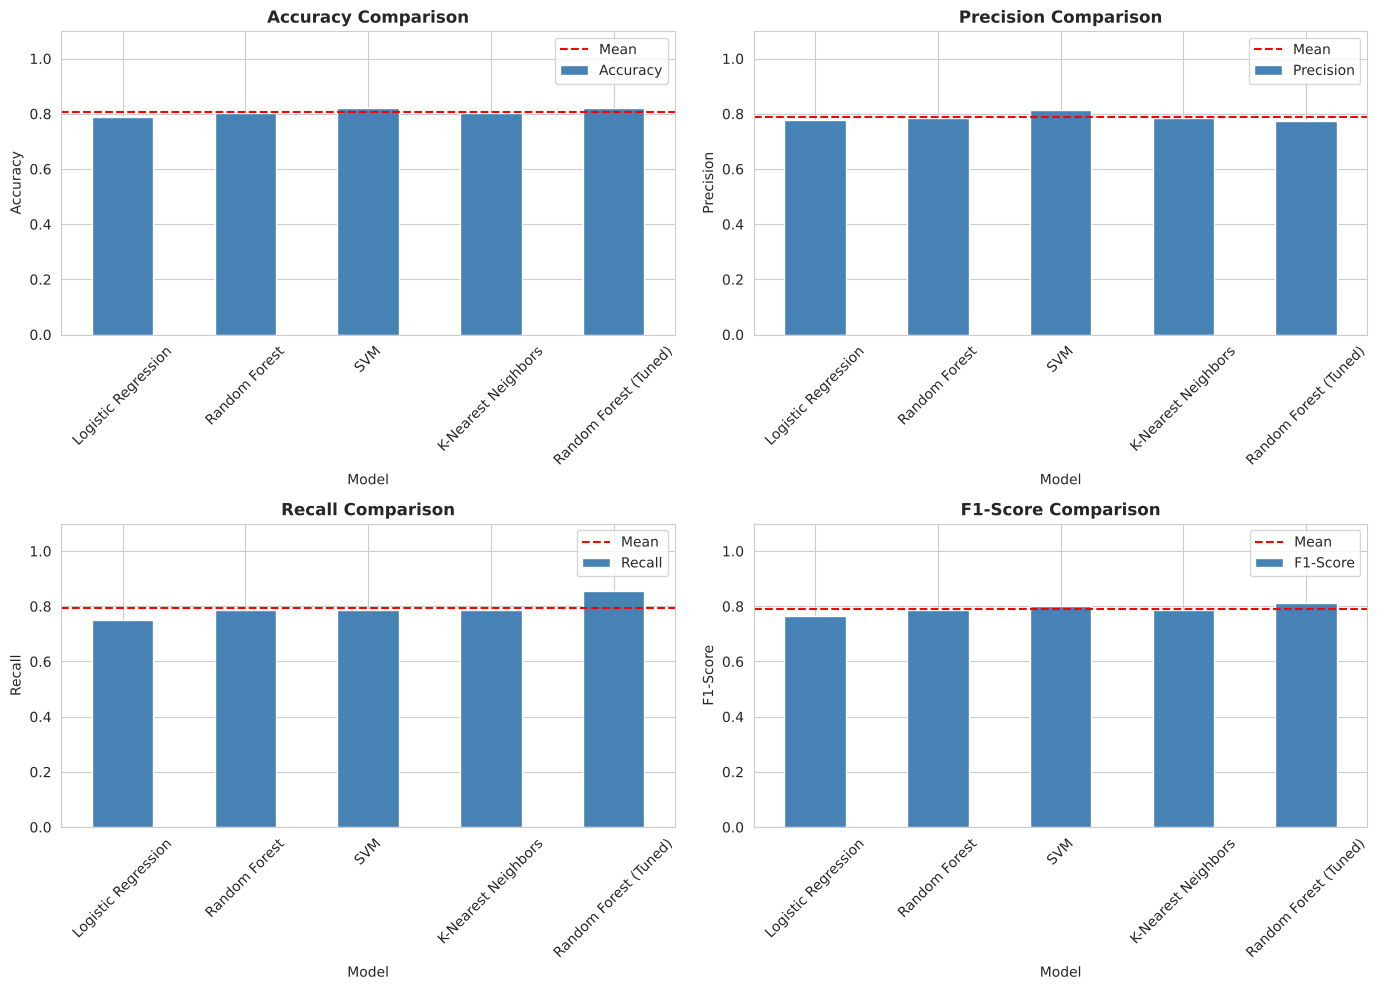

In [17]:
# ========================================
# 9. MODEL COMPARISON
# ========================================
print("\n" + "="*50)
print("MODEL COMPARISON")
print("="*50)

# Create comparison dataframe
comparison_df = pd.DataFrame(results).T
comparison_df = comparison_df.round(4)
print("\n", comparison_df)
print("\n")

# Visualize comparison
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score']

for idx, metric in enumerate(metrics):
    row = idx // 2
    col = idx % 2
    comparison_df[metric].plot(kind='bar', ax=axes[row, col], color='steelblue')
    axes[row, col].set_title(f'{metric} Comparison', fontweight='bold')
    axes[row, col].set_ylabel(metric)
    axes[row, col].set_xlabel('Model')
    axes[row, col].set_ylim([0, 1.1])
    axes[row, col].axhline(y=comparison_df[metric].mean(), color='red',
                           linestyle='--', label='Mean')
    axes[row, col].legend()
    axes[row, col].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig('images/model_comparison.png', dpi=300)
plt.show()


CONFUSION MATRICES


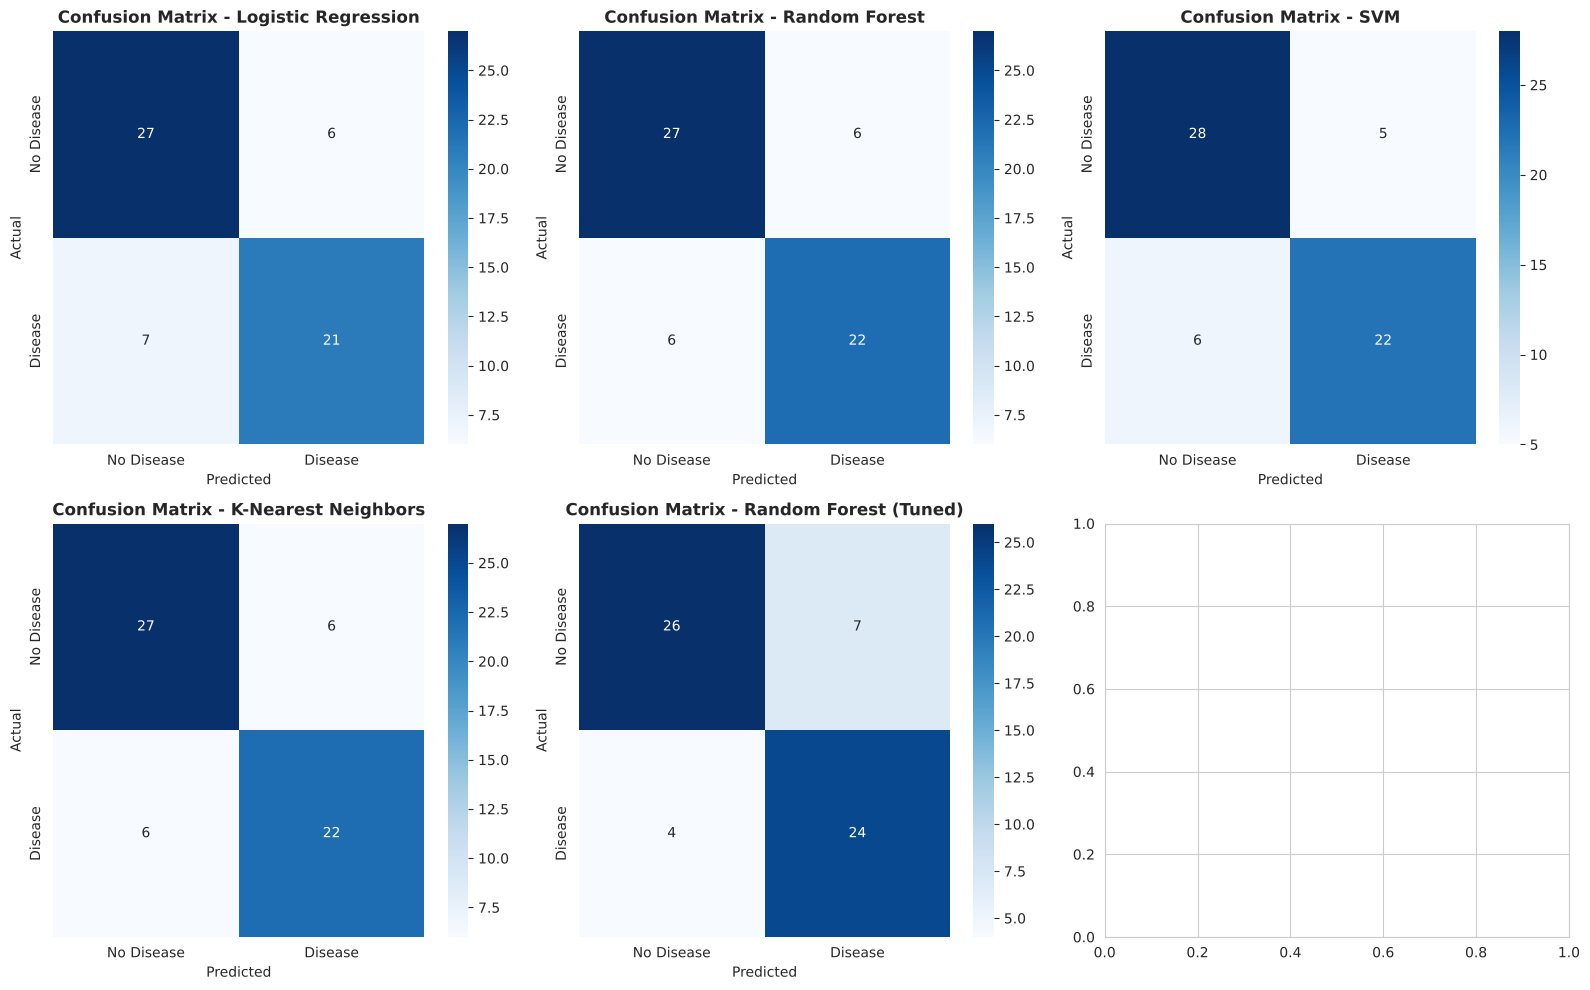

In [18]:
# ========================================
# 10. CONFUSION MATRICES
# ========================================
print("\n" + "="*50)
print("CONFUSION MATRICES")
print("="*50)

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.ravel()

for idx, (name, y_pred) in enumerate(predictions.items()):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx],
                xticklabels=['No Disease', 'Disease'],
                yticklabels=['No Disease', 'Disease'])
    axes[idx].set_title(f'Confusion Matrix - {name}', fontweight='bold')
    axes[idx].set_ylabel('Actual')
    axes[idx].set_xlabel('Predicted')

plt.tight_layout()
plt.savefig('images/confusion_matrices.png', dpi=300)
plt.show()

## 10. Repeated cross-validation

With 61 test patients, one patient is worth 1.6 points of accuracy, so the ranking above could flip with a different random split. Repeated stratified 5-fold cross-validation on the 241 training patients gives each model 50 scores instead of one, which shows whether the gaps between models are real or just noise. The scaler sits inside the pipeline, so every fold is scaled with its own training part only.

In [19]:
# ========================================
# 10b. REPEATED CROSS-VALIDATION
# ========================================
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline

cv_models = {
    'Logistic Regression': LogisticRegression(random_state=42, max_iter=1000),
    'Random Forest': RandomForestClassifier(random_state=42),
    'SVM': SVC(random_state=42, probability=True),
    'K-Nearest Neighbors': KNeighborsClassifier(),
    'Random Forest (Tuned)': RandomForestClassifier(random_state=42, **grid_search.best_params_),
}
repeated_cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=42)
cv_metrics = {'Accuracy': 'accuracy', 'Recall': 'recall', 'ROC-AUC': 'roc_auc'}

cv_results = {}
for name, model in cv_models.items():
    scores = cross_validate(make_pipeline(StandardScaler(), model), X_train, y_train,
                            cv=repeated_cv, scoring=cv_metrics, n_jobs=-1)
    cv_results[name] = {}
    for metric in cv_metrics:
        values = scores[f'test_{metric}']
        cv_results[name][metric] = f'{values.mean():.3f} ± {values.std():.3f}'

print('Repeated stratified 5-fold CV on the 241 training patients (10 repeats, 50 scores per model)\n')
print(pd.DataFrame(cv_results).T)

Repeated stratified 5-fold CV on the 241 training patients (10 repeats, 50 scores per model)

                            Accuracy         Recall        ROC-AUC
Logistic Regression    0.831 ± 0.056  0.761 ± 0.086  0.904 ± 0.044
Random Forest          0.827 ± 0.053  0.759 ± 0.091  0.908 ± 0.042
SVM                    0.822 ± 0.047  0.729 ± 0.100  0.895 ± 0.044
K-Nearest Neighbors    0.814 ± 0.051  0.719 ± 0.099  0.868 ± 0.055
Random Forest (Tuned)  0.828 ± 0.053  0.764 ± 0.085  0.909 ± 0.038


All five models land within about one standard deviation of each other on every metric, so the single-split ranking above is mostly noise: on the test set, the gap between Logistic Regression (0.79) and the SVM (0.82) is two patients. Logistic Regression has the highest mean accuracy here (0.83), a recall in line with the best, and it's the only model whose coefficients a clinician can read one by one. That's why it's the final model, chosen here rather than from a single 61-patient split.

## 11. ROC curves


ROC-AUC ANALYSIS
Logistic Regression - AUC: 0.8896
Random Forest - AUC: 0.8815
SVM - AUC: 0.8842
K-Nearest Neighbors - AUC: 0.8755
Random Forest (Tuned) - AUC: 0.8907




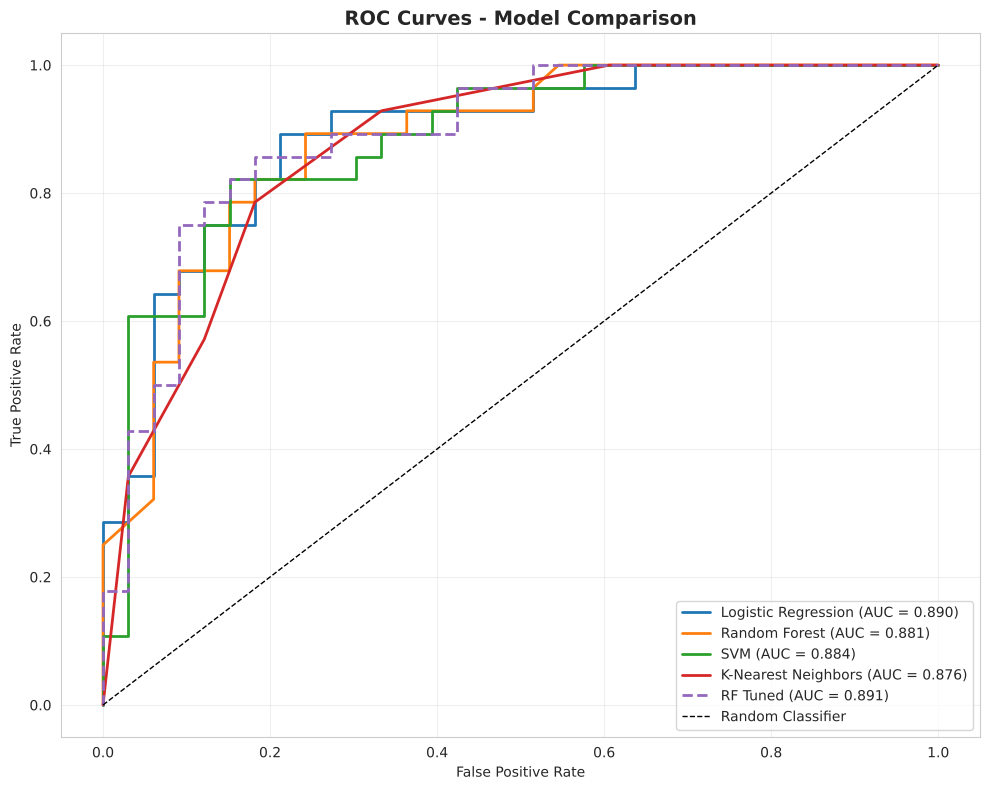

In [20]:
# ========================================
# 11. ROC CURVES
# ========================================
print("\n" + "="*50)
print("ROC-AUC ANALYSIS")
print("="*50)

plt.figure(figsize=(10, 8))

for name, model in models.items():
    if hasattr(model, 'predict_proba'):
        y_proba = model.predict_proba(X_test_scaled)[:, 1]
        fpr, tpr, _ = roc_curve(y_test, y_proba)
        auc = roc_auc_score(y_test, y_proba)
        plt.plot(fpr, tpr, label=f'{name} (AUC = {auc:.3f})', linewidth=2)
        print(f"{name} - AUC: {auc:.4f}")

# Tuned Random Forest
y_proba_tuned = best_rf.predict_proba(X_test_scaled)[:, 1]
fpr_tuned, tpr_tuned, _ = roc_curve(y_test, y_proba_tuned)
auc_tuned = roc_auc_score(y_test, y_proba_tuned)
plt.plot(fpr_tuned, tpr_tuned, label=f'RF Tuned (AUC = {auc_tuned:.3f})',
         linewidth=2, linestyle='--')
print(f"Random Forest (Tuned) - AUC: {auc_tuned:.4f}")
print("\n")

plt.plot([0, 1], [0, 1], 'k--', linewidth=1, label='Random Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves - Model Comparison', fontweight='bold', fontsize=14)
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('images/roc_curves.png', dpi=300)
plt.show()

## 12. Feature importance


FEATURE IMPORTANCE ANALYSIS

      Feature  Importance
11        ca    0.168232
2         cp    0.144896
9    oldpeak    0.110116
12      thal    0.106013
7    thalach    0.103233
8      exang    0.099433
0        age    0.070758
10     slope    0.054416
4       chol    0.048775
1        sex    0.039733
3   trestbps    0.039203
6    restecg    0.008633
5        fbs    0.006560




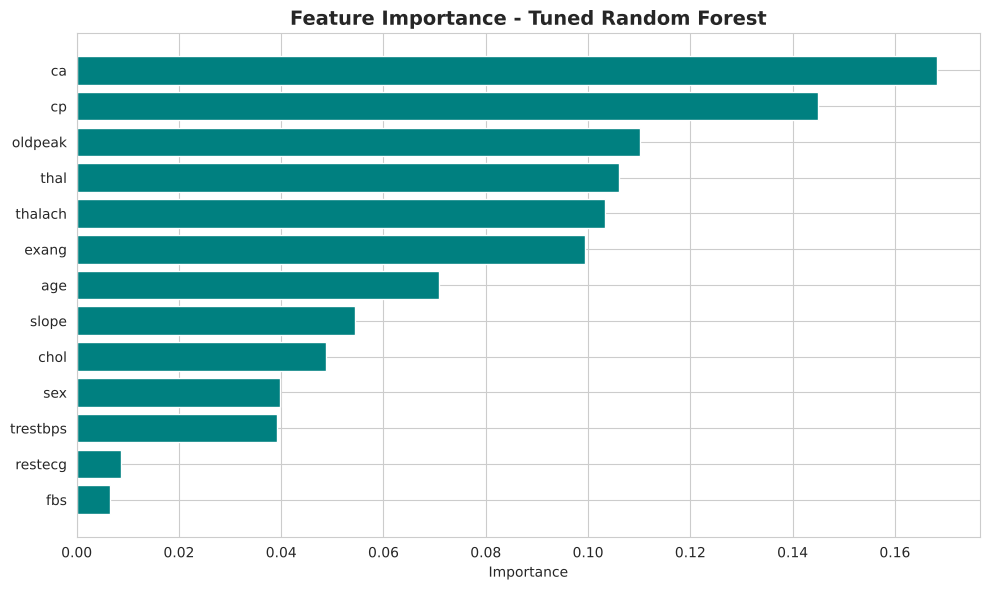

In [21]:
# ========================================
# 12. FEATURE IMPORTANCE (Random Forest)
# ========================================
print("\n" + "="*50)
print("FEATURE IMPORTANCE ANALYSIS")
print("="*50)

feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': best_rf.feature_importances_
}).sort_values('Importance', ascending=False)

print("\n", feature_importance)
print("\n")

plt.figure(figsize=(10, 6))
plt.barh(feature_importance['Feature'], feature_importance['Importance'], color='teal')
plt.xlabel('Importance')
plt.title('Feature Importance - Tuned Random Forest', fontweight='bold', fontsize=14)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig('images/feature_importance.png', dpi=300)
plt.show()

## 13. Summary

In [22]:
# ========================================
# 13. SUMMARY
# ========================================
print("\n" + "="*50)
print("RESULTS SUMMARY")
print("="*50)

# Chosen by the repeated cross-validation in section 10, not by one 61-patient split
best_model_name = 'Logistic Regression'
best_accuracy = comparison_df.loc[best_model_name, 'Accuracy']

print(f"FINAL MODEL: {best_model_name}")
print(f"Accuracy: {best_accuracy:.4f}")
print(f"Precision: {comparison_df.loc[best_model_name, 'Precision']:.4f}")
print(f"Recall: {comparison_df.loc[best_model_name, 'Recall']:.4f}")
print(f"F1-Score: {comparison_df.loc[best_model_name, 'F1-Score']:.4f}")

print("\n" + "="*50)
print("CLASSIFICATION REPORT")
print("="*50)
print(f"\n{best_model_name}:")
print(classification_report(y_test, predictions[best_model_name],
                          target_names=['No Disease', 'Disease']))



RESULTS SUMMARY
FINAL MODEL: Logistic Regression
Accuracy: 0.7869
Precision: 0.7778
Recall: 0.7500
F1-Score: 0.7636

CLASSIFICATION REPORT

Logistic Regression:
              precision    recall  f1-score   support

  No Disease       0.79      0.82      0.81        33
     Disease       0.78      0.75      0.76        28

    accuracy                           0.79        61
   macro avg       0.79      0.78      0.78        61
weighted avg       0.79      0.79      0.79        61



## Conclusions

- **Data quality first, twice.** With duplicates left in, 202 of 205 test rows also appear in the training set and a Random Forest scores a misleading **100%**. And the label in this Kaggle version is flipped (1 = healthy), which I caught by checking the two groups against clinical knowledge. Without that check, every "disease recall" would have been recall on healthy patients.
- **Final model: Logistic Regression**, chosen by repeated cross-validation: the highest mean accuracy (0.83 ± 0.06) with recall and ROC-AUC in line with the best model. On the 61 test patients it reaches accuracy 0.79 and ROC-AUC 0.89, and on the disease class recall 0.75, precision 0.78 and F1 0.76.
- **A single small split can't pick a winner.** On the test set the SVM and the tuned Random Forest score 0.82, but that's two patients out of 61, and in repeated CV every model sits within about one standard deviation of the others. When the models tie, I'd rather keep the one a clinician can read.
- Recall 0.75 means 7 of the 28 sick patients in the test set are missed. For a screening tool that's too many, so the next step is a lower threshold, chosen with cross-validation on the training data rather than on the test set.
- The most informative features are the number of major vessels (*ca*), chest-pain type, ST depression, thalassemia result and max heart rate, which is clinically plausible.
- **Next steps:** a recall-oriented threshold chosen by CV, and probability calibration, because a clinician will read the score as a probability.